# TGLF surrogate: prepare the data

Build the 5,000-case table, check data quality and distributions, select features
and target transformations, and fix the 70/15/15 train/validation/test split.
This covers Step 1 of [the assignment](Task2_TGLF_surrogate.docx.pdf).

Exploration and feature choices use training rows only. The same validity checks
apply to every split. The 43 Task 1 cases remain a separate outside evaluation.
Run this notebook with **Python (DSC180A)** from the course project. It reuses
[the Task 1 loader](../A1/analysis/sat3_loader.py) and writes to `prepared/`.

[1. Prepare data](01_prepare_data.ipynb) · [2. NN ensemble](02_nn_ensemble.ipynb) · [3. Evaluation](03_evaluation.ipynb)

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split

SEED = 42
EXPECTED_CASES = 5000
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data/scan_db/data").is_dir()
     and (p / "assignments/A1/analysis/sat3_loader.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the DSC180A project folder.")

DATA_DIR = ROOT / "data/scan_db/data"
NOTEBOOK_DIR = ROOT / "assignments/A2"
PREPARED_DIR = NOTEBOOK_DIR / "prepared"
FIGURE_DIR = NOTEBOOK_DIR / "figures"
for folder in (PREPARED_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "assignments/A1/analysis"))
from sat3_loader import load_cases, SCALAR_PARAMETERS, SPECIES_PARAMETERS

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", 12)
print(f"Source: {DATA_DIR}")
print(f"Random seed: {SEED}")

Source: /Users/ryanlindberg/Desktop/Classes/DSC180A/data/scan_db/data
Random seed: 42


## 1. Build the table using the Task 1 reader

Each case contributes `input.tglf.gen` and `out.tglf.gbflux`. The existing reader
checks required parameters, finite numeric values, species identity, and flux-file
length; it also understands Fortran exponents. Loading errors stop preparation.

The flux file contains four blocks in species order: particle flux, heat flux,
momentum flux, and energy exchange. For this two-species database, the first four
values are `Gamma_e, Gamma_i, Q_e, Q_i`. We verify the species ordering before
assigning these names. Flux values remain in their supplied gyro-Bohm units.

In [2]:
records, errors = load_cases(DATA_DIR)
load_errors = pd.DataFrame(errors, columns=["case", "error"])
print(f"Loaded {len(records):,} cases; {len(errors)} loading errors.")
if errors:
    display(load_errors)
    raise ValueError("Resolve the reported loading errors before continuing.")

df = pd.DataFrame(records).set_index("case").sort_index()
expected_ids = {f"r{i:04d}" for i in range(1, EXPECTED_CASES + 1)}
assert len(df) == EXPECTED_CASES and df.index.is_unique
assert set(df.index) == expected_ids, "Unexpected or missing case IDs."
assert df["NS"].eq(2).all()
assert df["species_type_1"].eq("electron").all()
assert df["species_type_2"].isin(["H", "D", "T"]).all()
assert np.isfinite(df.select_dtypes(include="number").to_numpy()).all()

INPUT_COLUMNS = list(SCALAR_PARAMETERS) + [
    f"{name}_{s}" for name in SPECIES_PARAMETERS for s in (1, 2)
]
TARGET_COLUMNS = ["Q_i", "Q_e", "Gamma_e"]
df["Q_i"] = df["Q_2"]
df["Q_e"] = df["Q_1"]
df["Gamma_e"] = df["Gamma_1"]
df["isotope"] = df["species_type_2"]

# Check the mapping against the labeled run output for one example.
def labeled_fluxes(case):
    rows = {}
    text = (DATA_DIR / case / "tglf_sat2/out.tglf.run").read_text()
    for line in text.splitlines():
        fields = line.split()
        if fields and fields[0] in {"elec", "ion1"}:
            rows[fields[0]] = [float(x.replace("D", "E")) for x in fields[1:]]
    return {"Q_i": rows["ion1"][1], "Q_e": rows["elec"][1],
            "Gamma_e": rows["elec"][0]}

example = "r0001"
np.testing.assert_allclose(
    df.loc[example, TARGET_COLUMNS].to_numpy(dtype=float),
    [labeled_fluxes(example)[name] for name in TARGET_COLUMNS],
)
print(f"Retained {len(INPUT_COLUMNS)} physical input columns and the raw flux columns.")
display(df[["isotope", "RLTS_1", "RLTS_2", "XNUE", *TARGET_COLUMNS]].head())

Loaded 5,000 cases; 0 loading errors.
Retained 19 physical input columns and the raw flux columns.


,isotope,RLTS_1,RLTS_2,XNUE,Q_i,Q_e,Gamma_e
case,,,,,,,
r0001,T,2.81135,3.01829,0.040633,234.2000,214.280,74.4260
r0002,D,1.93007,1.98400,0.010340,68.7260,105.530,44.5230
r0003,D,1.85239,3.15235,0.014209,436.8100,249.130,114.0400
r0004,H,3.06612,2.24544,0.021448,24.5350,34.577,2.7039
r0005,H,1.82297,1.95707,0.505177,4.9705,12.120,4.7500


## 2. Fix the split before exploration

Randomly assign all 5,000 case IDs to **70% training, 15% validation, and 15% test**
with seed 42. The second split divides the 30% holdout equally. These assignments
are saved and checked on reruns. A later quality flag does not move a case into
another split, and no split is redrawn to improve results.

In [3]:
train_ids, holdout_ids = train_test_split(
    df.index.to_numpy(), test_size=0.30, random_state=SEED
)
validation_ids, test_ids = train_test_split(
    holdout_ids, test_size=0.50, random_state=SEED
)
split = pd.Series(index=df.index, dtype="object", name="split")
for name, ids in [("train", train_ids), ("validation", validation_ids), ("test", test_ids)]:
    split.loc[ids] = name
assert split.notna().all()
assert set(train_ids).isdisjoint(validation_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(validation_ids).isdisjoint(test_ids)
assert split.value_counts().to_dict() == {"train": 3500, "validation": 750, "test": 750}

split_path = PREPARED_DIR / "split_assignments.csv"
if split_path.exists():
    saved_split = pd.read_csv(split_path, index_col="case")["split"]
    pd.testing.assert_series_equal(saved_split, split, check_dtype=False)
else:
    split.to_csv(split_path, index_label="case")

df["split"] = split
display(split.value_counts().reindex(["train", "validation", "test"]).rename("cases").to_frame())

,cases
split,
train,3500
validation,750
test,750


## 3. Check the inputs and flag questionable outputs

The two case files supply the actual simulation values. `samples.csv` is an
independent cross-check of case IDs, input values, and isotopes. Its values retain
more digits than `input.tglf.gen`, so comparisons allow the input file's rounding.
Magnetic shear is reconstructed using the same expression as Task 1:
`Q_PRIME_LOC * RMIN_LOC**2 / Q_LOC**2`, and checked against `samples.csv`.

The checks below cover missing/non-finite values, prescribed input ranges,
duplicate input vectors, equal species density gradients, and positive collision
frequency. Negative particle flux is allowed. Non-positive heat flux is flagged
for review because the task asks us to investigate it and `log10(Q)` requires
strictly positive values. A flag does not prove that the simulation is wrong.

In [4]:
manifest = pd.read_csv(ROOT / "data/scan_db/samples.csv").set_index("case")
assert manifest.index.is_unique and set(manifest.index) == set(df.index)
manifest = manifest.loc[df.index]
manifest_mapping = {
    "RLTS_1": "RLTS_1", "RLTS_2": "RLTS_2", "RLN": "RLNS_1",
    "TAUS_2": "TAUS_2", "XNUE": "XNUE", "Q_LOC": "Q_LOC",
    "KAPPA_LOC": "KAPPA_LOC", "DRMAJDX_LOC": "DRMAJDX_LOC",
    "RMIN_LOC": "RMIN_LOC",
}
for source_name, input_name in manifest_mapping.items():
    np.testing.assert_allclose(df[input_name], manifest[source_name], rtol=1e-5, atol=1e-8)
assert manifest["isotope"].equals(df["isotope"])
assert df["RLNS_1"].equals(df["RLNS_2"])
assert df["XNUE"].gt(0).all()

magnetic_shear = df["Q_PRIME_LOC"] * df["RMIN_LOC"]**2 / df["Q_LOC"]**2
np.testing.assert_allclose(magnetic_shear, manifest["SHEAR"], rtol=3e-5, atol=1e-7)

bounds = {
    "RLTS_1": (1.5, 3.5), "RLTS_2": (1.5, 3.5), "RLNS_1": (1.0, 3.0),
    "TAUS_2": (0.5, 1.5), "XNUE": (0.01, 1.0), "Q_LOC": (1.5, 2.5),
    "KAPPA_LOC": (1.0, 2.0), "DRMAJDX_LOC": (-0.5, 0.0), "RMIN_LOC": (0.25, 0.75),
}
range_checks = pd.DataFrame({
    name: ~df[name].between(lo - 1e-6, hi + 1e-6)
    for name, (lo, hi) in bounds.items()
})
assert not range_checks.any().any(), "Inspect inputs outside the assignment ranges."
assert df["MASS_2"].isin([0.5, 1.0, 1.5]).all()

quality = pd.DataFrame(index=df.index)
quality["missing_or_nonfinite"] = ~np.isfinite(df[INPUT_COLUMNS + TARGET_COLUMNS]).all(axis=1)
quality["input_out_of_range"] = range_checks.any(axis=1)
quality["duplicate_inputs"] = df[INPUT_COLUMNS].duplicated(keep=False)
quality["negative_Q_i"] = df["Q_i"].lt(0)
quality["negative_Q_e"] = df["Q_e"].lt(0)
quality["zero_heat_flux"] = df[["Q_i", "Q_e"]].eq(0).any(axis=1)
quality["negative_Gamma_e_allowed"] = df["Gamma_e"].lt(0)
assert not quality[["missing_or_nonfinite", "input_out_of_range", "duplicate_inputs"]].any().any()

heat_review = quality[["negative_Q_i", "negative_Q_e", "zero_heat_flux"]].any(axis=1)
df["quality_flag"] = np.where(heat_review, "review_heat_flux", "ok")
df["model_eligible"] = ~heat_review
display(quality.sum().rename("cases").to_frame())

# Inspect source labels for every heat-flux flag; never flip signs or clip values.
flagged = df.loc[heat_review, ["split", *TARGET_COLUMNS, "quality_flag"]].copy()
for case in flagged.index:
    reference = labeled_fluxes(case)
    np.testing.assert_allclose(
        df.loc[case, TARGET_COLUMNS].to_numpy(dtype=float),
        [reference[name] for name in TARGET_COLUMNS],
    )
flagged["matches_labeled_run"] = True
display(flagged)

split_summary = df.groupby("split").agg(
    assigned_cases=("model_eligible", "size"), usable_cases=("model_eligible", "sum")
).reindex(["train", "validation", "test"])
split_summary["held_for_review"] = split_summary["assigned_cases"] - split_summary["usable_cases"]
display(split_summary)

,cases
missing_or_nonfinite,0
input_out_of_range,0
duplicate_inputs,0
negative_Q_i,4
negative_Q_e,0
zero_heat_flux,0
negative_Gamma_e_allowed,47


,split,Q_i,Q_e,Gamma_e,quality_flag,matches_labeled_run
case,,,,,,
r0702,train,-16.668000,236.6000,1.587000,review_heat_flux,True
r2002,train,-0.241370,31.9940,-0.012923,review_heat_flux,True
r2828,train,-0.018705,6.8269,-0.013826,review_heat_flux,True
r3565,train,-1.650400,30.4410,0.102810,review_heat_flux,True


,assigned_cases,usable_cases,held_for_review
split,,,
train,3500,3496,4
validation,750,750,0
test,750,750,0


**Quality decision.** Keep all 5,000 cases in the full table. Hold the four
negative-ion-heat cases (`r0702`, `r2002`, `r2828`, `r3565`) out of the modeling
tables pending physics/solver review. Their signs agree with `out.tglf.run`, so
they are not a flux-column parsing mistake. All four were assigned to training,
leaving **3,496 training, 750 validation, and 750 test cases** eligible for modeling.
The original 3,500/750/750 split assignments stay fixed.

There are 47 negative electron particle fluxes in the full table. Two occur in
the four cases held for heat-flux review; the other 45 remain model-eligible.
Particle-flux sign is never a reason for exclusion. There are no zero heat fluxes,
loading failures, non-finite values, or duplicate retained input vectors.
These checks do not establish solver convergence.

## 4. Select features using the training inputs

Use 11 physical coordinates. Unlike Task 1, electron and ion temperature
gradients vary independently, so keep **both** `RLTS_1` and `RLTS_2`.

| Choice | Reason |
| --- | --- |
| Keep one density gradient (`RLNS_1`) | `RLNS_2` is identical. |
| Use `log10_XNUE` | Collision frequency was sampled on a log scale. |
| Use derived `magnetic_shear` | It replaces `Q_PRIME_LOC` while retaining `Q_LOC` and `RMIN_LOC`. |
| Use `MASS_2` | It numerically represents H, D, and T; the isotope label is redundant. |
| Drop constant inputs | They contain no variation for a model to learn from. |
| Exclude case ID, quality flags, and other fluxes | They are identifiers, review metadata, or outputs, not plasma inputs. |

No learned scaler is fitted yet. If a later model needs standardization, fit the
scaler on training rows only and apply that same scaler to validation and test.

In [5]:
training = df.loc[df["split"].eq("train") & df["model_eligible"]].copy()
input_audit = pd.DataFrame({"training_distinct_values": training[INPUT_COLUMNS].nunique()})
constant_inputs = input_audit.index[input_audit["training_distinct_values"].eq(1)].tolist()
varying_inputs = [name for name in INPUT_COLUMNS if name not in constant_inputs]
duplicate_pairs = [
    (left, right)
    for i, left in enumerate(varying_inputs)
    for right in varying_inputs[i + 1:]
    if training[left].equals(training[right])
]
print("Constant inputs:", ", ".join(constant_inputs))
print("Identical varying inputs:", duplicate_pairs)
display(input_audit)

DIRECT_FEATURES = [
    "RLTS_1", "RLTS_2", "RLNS_1", "TAUS_2", "Q_LOC",
    "KAPPA_LOC", "DRMAJDX_LOC", "RMIN_LOC", "MASS_2",
]
FEATURE_COLUMNS = [*DIRECT_FEATURES, "log10_XNUE", "magnetic_shear"]

def make_features(table):
    # Apply these same deterministic formulas to the Task 1 cases in Step 5.
    if table["XNUE"].le(0).any() or table["Q_LOC"].eq(0).any():
        raise ValueError("Feature transforms require positive XNUE and nonzero Q_LOC.")
    result = table[DIRECT_FEATURES].copy()
    result["log10_XNUE"] = np.log10(table["XNUE"])
    result["magnetic_shear"] = table["Q_PRIME_LOC"] * table["RMIN_LOC"]**2 / table["Q_LOC"]**2
    return result[FEATURE_COLUMNS]

X_all = make_features(df)
X_train_view = X_all.loc[training.index]
assert X_all.shape == (EXPECTED_CASES, 11)
assert np.isfinite(X_all).all().all()
assert X_train_view.nunique().gt(1).all()
print(f"Selected {X_all.shape[1]} features.")
display(X_train_view.head())

Constant inputs: NS, MASS_1, ZS_1, ZS_2, TAUS_1, AS_1, AS_2
Identical varying inputs: [('RLNS_1', 'RLNS_2')]


,training_distinct_values
NS,1
XNUE,3496
RMIN_LOC,3496
KAPPA_LOC,3495
Q_LOC,3496
Q_PRIME_LOC,3492
DRMAJDX_LOC,3496
MASS_1,1
MASS_2,3
ZS_1,1


Selected 11 features.


,RLTS_1,RLTS_2,RLNS_1,TAUS_2,Q_LOC,KAPPA_LOC,DRMAJDX_LOC,RMIN_LOC,MASS_2,log10_XNUE,magnetic_shear
case,,,,,,,,,,,
r0001,2.81135,3.01829,2.80438,1.054800,1.87982,1.90565,-0.301454,0.682206,1.5,-1.391125,1.125594
r0002,1.93007,1.98400,2.94046,0.757593,2.03636,1.10329,-0.100730,0.686258,1.0,-1.985492,0.851539
r0003,1.85239,3.15235,2.94453,1.353670,1.68992,1.42100,-0.451069,0.493435,1.0,-1.847446,0.958752
r0004,3.06612,2.24544,1.22115,0.550256,2.03534,1.96162,-0.339993,0.412764,0.5,-1.668609,0.851124
r0005,1.82297,1.95707,2.94536,0.582532,1.60402,1.12368,-0.417308,0.656917,0.5,-0.296556,0.285194


## 5. Inspect training input histograms

The sampled continuous coordinates should be roughly flat over their ranges.
Use `log10(XNUE)` for the collision histogram, and show ion mass as three discrete
counts. `Q_PRIME_LOC` is derived from shear, safety factor, and radius, so it is
not expected to have a flat histogram. Small bin-count fluctuations are expected
from random sampling; holding four cases for review can also change counts.

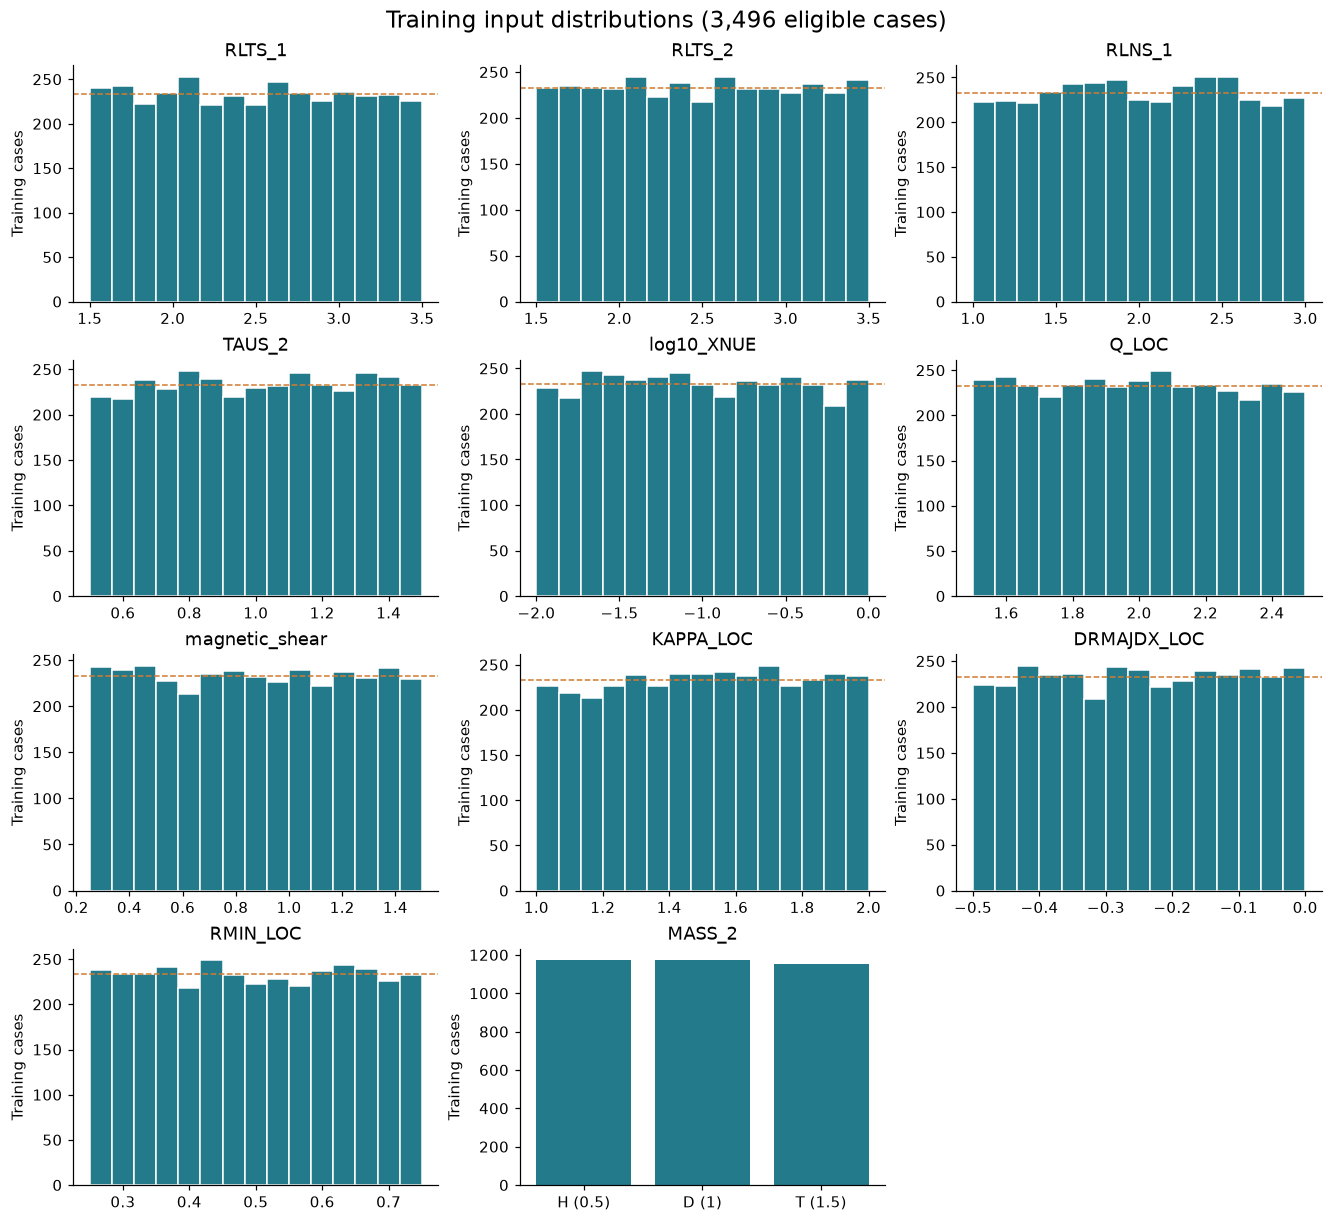

,smallest_bin,largest_bin,equal_bin_count
feature,,,
RLTS_1,221,253,233.1
RLTS_2,217,245,233.1
RLNS_1,218,251,233.1
TAUS_2,217,248,233.1
log10_XNUE,209,247,233.1
Q_LOC,217,249,233.1
magnetic_shear,213,244,233.1
KAPPA_LOC,213,249,233.1
DRMAJDX_LOC,209,245,233.1


In [6]:
histogram_specs = [
    ("RLTS_1", (1.5, 3.5)), ("RLTS_2", (1.5, 3.5)), ("RLNS_1", (1, 3)),
    ("TAUS_2", (0.5, 1.5)), ("log10_XNUE", (-2, 0)), ("Q_LOC", (1.5, 2.5)),
    ("magnetic_shear", None), ("KAPPA_LOC", (1, 2)), ("DRMAJDX_LOC", (-0.5, 0)),
    ("RMIN_LOC", (0.25, 0.75)), ("MASS_2", None),
]
fig, axes = plt.subplots(4, 3, figsize=(12, 11), constrained_layout=True)
bin_summary = []
for ax, (name, limits) in zip(axes.flat, histogram_specs):
    values = X_train_view[name]
    if name == "MASS_2":
        counts = values.value_counts().reindex([0.5, 1.0, 1.5], fill_value=0)
        ax.bar(["H (0.5)", "D (1)", "T (1.5)"], counts, color="#237a8a")
    else:
        counts, _, _ = ax.hist(values, bins=15, range=limits, color="#237a8a", edgecolor="white")
        ax.axhline(len(values) / 15, color="#d17b30", linestyle="--", linewidth=1)
        bin_summary.append({"feature": name, "smallest_bin": int(min(counts)),
                            "largest_bin": int(max(counts)), "equal_bin_count": len(values) / 15})
    ax.set(title=name, ylabel="Training cases")
axes.flat[-1].set_visible(False)
fig.suptitle(f"Training input distributions ({len(training):,} eligible cases)", fontsize=15)
fig.savefig(FIGURE_DIR / "01_training_inputs.png", bbox_inches="tight")
plt.show()
display(pd.DataFrame(bin_summary).set_index("feature").round(1))

The training inputs cover the intended ranges without the repeated reference
settings seen in the Task 1 scan. The continuous histograms are approximately
flat in the sampled coordinates, and all three ion masses are represented.
The collision distribution is approximately flat **after taking log10**, as the
sampling design specifies.

## 6. Inspect output scales and choose target transformations

Use only eligible training rows for these comparisons. The flagged heat values
remain visible in Section 3 and in the full exported table. Large positive
fluxes are retained; size alone is not evidence of a failed simulation.

,count,mean,std,min,1%,50%,99%,max,negative_count,skew_raw,positive_max_over_min
Q_i,3496.0,64.0358,88.4060,0.1214,1.1371,34.9545,438.1810,1050.40,0,3.7965,8655.9539
Q_e,3496.0,51.1697,72.6304,0.0489,1.7624,25.3430,357.4875,813.52,0,3.8005,16643.8889
Gamma_e,3496.0,16.1386,25.3145,-5.0258,0.0205,7.0056,131.2430,283.13,34,3.9038,320467.6906


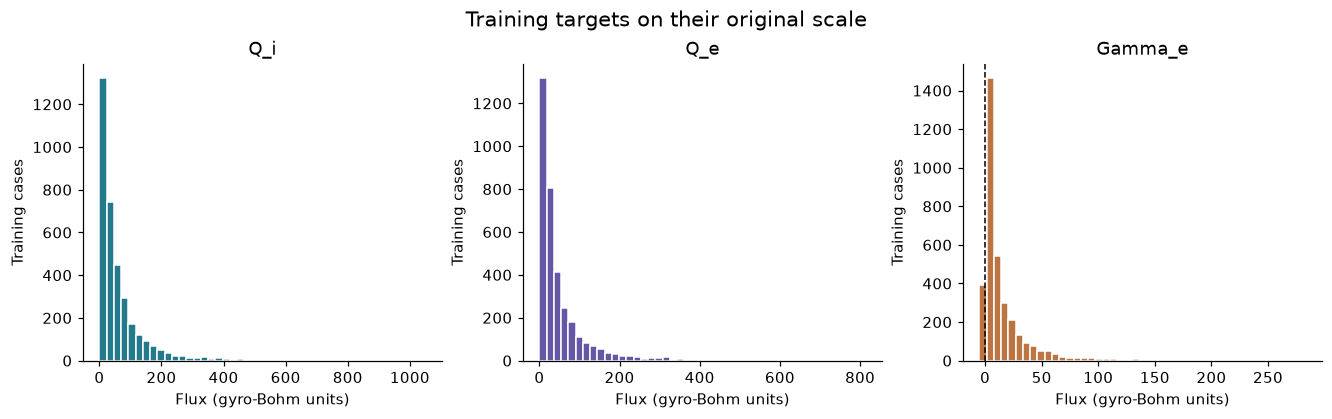

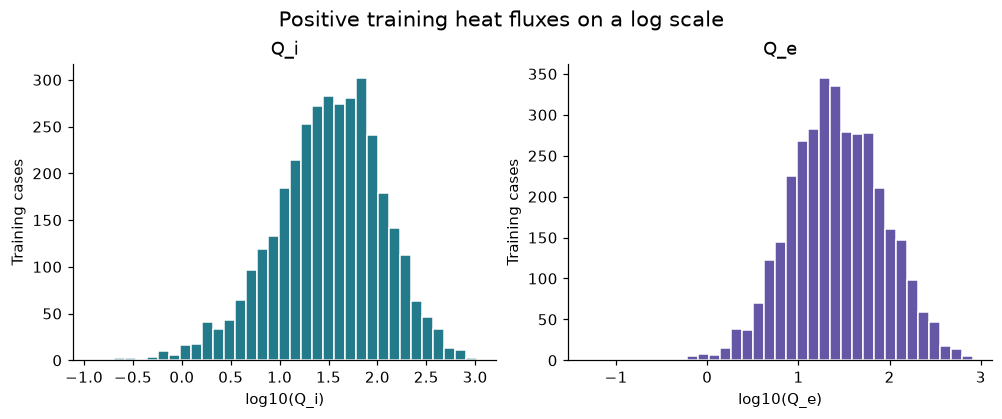

,raw_skew,log10_skew,log10_min,log10_max
Q_i,3.796,-0.406,-0.916,3.021
Q_e,3.800,-0.058,-1.311,2.910


In [7]:
y_training = training[TARGET_COLUMNS]
target_summary = y_training.describe(percentiles=[0.01, 0.5, 0.99]).T
target_summary["negative_count"] = y_training.lt(0).sum()
target_summary["skew_raw"] = y_training.skew()
target_summary["positive_max_over_min"] = y_training.where(y_training.gt(0)).max() / y_training.where(y_training.gt(0)).min()
display(target_summary.round(4))

colors = ["#237a8a", "#6556a6", "#bc7440"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), constrained_layout=True)
for ax, name, color in zip(axes, TARGET_COLUMNS, colors):
    ax.hist(y_training[name], bins=45, color=color, edgecolor="white")
    ax.set(title=name, xlabel="Flux (gyro-Bohm units)", ylabel="Training cases")
    if name == "Gamma_e":
        ax.axvline(0, color="black", linewidth=1, linestyle="--")
fig.suptitle("Training targets on their original scale", fontsize=14)
fig.savefig(FIGURE_DIR / "02_training_targets_raw.png", bbox_inches="tight")
plt.show()

log_heat = np.log10(y_training[["Q_i", "Q_e"]])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7), constrained_layout=True)
for ax, name, color in zip(axes, ["Q_i", "Q_e"], colors):
    ax.hist(log_heat[name], bins=35, color=color, edgecolor="white")
    ax.set(title=name, xlabel=f"log10({name})", ylabel="Training cases")
fig.suptitle("Positive training heat fluxes on a log scale", fontsize=14)
fig.savefig(FIGURE_DIR / "03_training_heat_log10.png", bbox_inches="tight")
plt.show()

transform_comparison = pd.DataFrame({
    "raw_skew": y_training[["Q_i", "Q_e"]].skew(),
    "log10_skew": log_heat.skew(),
    "log10_min": log_heat.min(), "log10_max": log_heat.max(),
})
display(transform_comparison.round(3))

**Target choice:** predict `log10(Q_i)` and `log10(Q_e)`, and predict `Gamma_e`
directly. The positive heat fluxes span several orders of magnitude and have
long upper tails; the log-scale histograms and skew comparison support this
starting choice. Particle flux can be negative, so taking its ordinary logarithm
would be invalid. We preserve its sign and leave it on the original scale.

Log-space heat losses emphasize proportional errors and change the optimization
objective. A lower log-space error does not guarantee a lower original-scale
RMSE. Later model settings and any alternative target transform should be
chosen on validation data. For final RMSE, R², and parity plots, convert heat
predictions back with `10**prediction` and compare against original flux values.

In [8]:
def transform_targets(raw_targets):
    if raw_targets[["Q_i", "Q_e"]].le(0).any().any():
        raise ValueError("Resolve non-positive heat flux before the log10 transform.")
    return pd.DataFrame({
        "log10_Q_i": np.log10(raw_targets["Q_i"]),
        "log10_Q_e": np.log10(raw_targets["Q_e"]),
        "Gamma_e": raw_targets["Gamma_e"],
    }, index=raw_targets.index)

def inverse_targets(model_targets):
    return pd.DataFrame({
        "Q_i": 10.0 ** model_targets["log10_Q_i"],
        "Q_e": 10.0 ** model_targets["log10_Q_e"],
        "Gamma_e": model_targets["Gamma_e"],
    }, index=model_targets.index)

eligible_ids = df.index[df["model_eligible"]]
X = X_all.loc[eligible_ids].copy()
y_raw = df.loc[eligible_ids, TARGET_COLUMNS].copy()
y_model = transform_targets(y_raw)
np.testing.assert_allclose(inverse_targets(y_model), y_raw, rtol=1e-12, atol=1e-12)
assert np.isfinite(X).all().all() and np.isfinite(y_model).all().all()

# Separate matrices ready for later steps; scaling, fitting, and tuning come later.
datasets = {}
for name in ("train", "validation", "test"):
    ids = df.index[df["split"].eq(name) & df["model_eligible"]]
    datasets[name] = {"X": X.loc[ids], "y_raw": y_raw.loc[ids], "y_model": y_model.loc[ids]}
    assert datasets[name]["X"].index.equals(datasets[name]["y_raw"].index)
    assert datasets[name]["X"].index.equals(datasets[name]["y_model"].index)

X_train, X_val, X_test = (datasets[name]["X"] for name in ("train", "validation", "test"))
y_train, y_val, y_test = (datasets[name]["y_model"] for name in ("train", "validation", "test"))
y_train_raw, y_val_raw, y_test_raw = (datasets[name]["y_raw"] for name in ("train", "validation", "test"))
assert sum(len(part["X"]) for part in datasets.values()) == len(eligible_ids)
display(pd.DataFrame({
    name: {"cases": len(part["X"]), "features": part["X"].shape[1], "targets": part["y_model"].shape[1]}
    for name, part in datasets.items()
}).T)

,cases,features,targets
train,3496,11,3
validation,750,11,3
test,750,11,3


## 7. Save and verify the prepared data

`scan_db_table.csv` keeps all parsed inputs and fluxes, the three named targets,
isotope, split, review flag, and eligibility. `split_assignments.csv` keeps all
5,000 original assignments. The feature and target tables contain only eligible
cases and use case ID as the join key. `quality_checks.csv` records each check.
`preparation_metadata.json` records the feature order, transformations, seed,
excluded IDs, counts, package versions, and source/export checksums.

Future steps should load these fixed assignments. Test targets are saved for
final evaluation; do not use them to select a model or transformation.

In [9]:
exports = {
    "scan_db_table.csv": df,
    "quality_checks.csv": quality,
    "features.csv": X,
    "targets_raw.csv": y_raw,
    "targets_model.csv": y_model,
}
for filename, table in exports.items():
    path = PREPARED_DIR / filename
    table.to_csv(path, index_label="case")
    loaded = pd.read_csv(path, index_col="case", float_precision="round_trip")
    # CSV preserves these values, but not pandas' in-memory string dtype.
    pd.testing.assert_frame_equal(loaded, table, check_exact=True, check_dtype=False)

pd.testing.assert_series_equal(pd.read_csv(split_path, index_col="case")["split"], split, check_dtype=False)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

metadata = {
    "scope": "Task 2, Step 1 only",
    "data_source": "data/scan_db/data",
    "loader": "assignments/A1/analysis/sat3_loader.py",
    "random_seed": SEED,
    "split_proportions": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "split_order": "Sort case IDs; sklearn train_test_split 30% holdout, then halve holdout; seed 42 for both.",
    "counts": split_summary.astype(int).to_dict(orient="index"),
    "features": FEATURE_COLUMNS,
    "constant_inputs_dropped": constant_inputs,
    "duplicate_input_dropped": "RLNS_2 equals RLNS_1",
    "feature_transforms": {"log10_XNUE": "log10(XNUE)", "magnetic_shear": "Q_PRIME_LOC * RMIN_LOC**2 / Q_LOC**2"},
    "raw_targets": TARGET_COLUMNS,
    "model_targets": list(y_model.columns),
    "target_transforms": {"Q_i": "log10", "Q_e": "log10", "Gamma_e": "identity"},
    "heat_inverse_transform": "10**prediction",
    "flux_units": "gyro-Bohm normalization from out.tglf.gbflux",
    "excluded_cases": df.index[~df["model_eligible"]].tolist(),
    "exclusion_policy": "Hold non-positive heat fluxes for review; retain originals and split assignments. Negative Gamma_e is allowed.",
    "fitted_preprocessing": "None; any future learned scaler must be fitted on training rows only.",
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "checksums_sha256": {
        "samples.csv": sha256(ROOT / "data/scan_db/samples.csv"),
        "sat3_loader.py": sha256(ROOT / "assignments/A1/analysis/sat3_loader.py"),
        **{name: sha256(PREPARED_DIR / name) for name in [*exports, "split_assignments.csv"]},
    },
}
(PREPARED_DIR / "preparation_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print(f"Saved and verified {len(df):,} source cases and {len(X):,} model-eligible cases.")
print(f"Tables: {PREPARED_DIR}")
print(f"Figures: {FIGURE_DIR}")

Saved and verified 5,000 source cases and 4,996 model-eligible cases.
Tables: /Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/A2/prepared
Figures: /Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/A2/figures


The modeling data contain **3,496 training, 750 validation, and 750 test cases**,
with 11 input features and three targets. Four negative-ion-heat cases are held
for review. Heat targets use log10; particle flux keeps its signed values.
Continue to [the NN ensemble](02_nn_ensemble.ipynb).